#### MRC_File implementation 

In [1]:
import numpy as np
import mrcfile
from tqdm import tqdm

class MRC_FILE(object):
    def __init__(self):
        self.xdim, self.ydim, self.zdim = 0, 0, 0
        self.angstromX, self.angstromY, self.angstromZ = 0, 0, 0
        self.origin = 0
        self.orientation = 0
    
    def read_mrc(self, mrc_file_path):
        with mrcfile.open(mrc_file_path) as mrc:
            self.angstromX, self.angstromY, self.angstromZ = float(mrc.header.cella.x.item()), float(mrc.header.cella.y.item()), float(mrc.header.cella.z.item())  # cell dimensions
            self.xdim, self.ydim, self.zdim = int(mrc.header.nx.item()), int(mrc.header.ny.item()), int(mrc.header.nz.item()) #Determine Shape of Array
            self.orientation = [mrc.header.mapc.item(), mrc.header.mapr.item(), mrc.header.maps.item()] #Determine Orientation of Array
            self.origin = [mrc.header.nxstart.item(), mrc.header.nystart.item(), mrc.header.nzstart.item()]
            self.originial_density = np.array(mrc.data)
            mrc.close()
        
        print("=== MRC File Read ===")
        print(f"EM_map Shape: {self.originial_density.shape}")
        print(f"Cell Dimensions (angstroms): {self.angstromX, self.angstromY, self.angstromZ}")
        print(f"Array Dimensions: {self.xdim, self.ydim, self.zdim}")
        print(f"Orientation (MAPC, MAPR, MAPS): {self.orientation}")
        print(f"Origin: {self.origin}")
        print("=======================")
        
    def filter_uNet_SS(self, uNet_map_path_SS):
        with mrcfile.open(uNet_map_path_SS) as mrc:
            self.uNet_map_SS = np.squeeze(mrc.data)
            mrc.close()
                        
        print("=== uNet Map Read ===")
        print(f"uNet_map Shape: {self.uNet_map_SS.shape}")
        print("=======================")
        
    def filter_uNet_KA(self, uNet_map_path_KA):
        with mrcfile.open(uNet_map_path_KA) as mrc:
            self.uNet_map_KA = np.squeeze(mrc.data)
            mrc.close()
                        
        print("=== uNet Map Read ===")
        print(f"uNet_map Shape: {self.uNet_map_KA.shape}")
        print("=======================")

#### Points Implementation

In [2]:
class points(object):
    def __init__(self):
                
        self.pseudo_coords = 0
        self.ps_dens = 0
        self.ps_count = 0
        
        self.merged_points = 0
        self.merged_density = 0
        
        self.final_coords = 0
        self.final_dens = 0
        self.final_coord_count = 0

    def find_coords(self, mrc, params, threshold=0.80):
               
        og_dens = np.copy(mrc.originial_density)
        
        if(params == 0):        
            uNet_map_KA = np.copy(mrc.uNet_map_KA)
            uNet_map_SS = np.copy(mrc.uNet_map_SS)
            uNet_map_KA[uNet_map_SS < threshold] = 0              
            uNet_map = np.copy(uNet_map_KA*uNet_map_SS)   
            print("Secondary Structure Considered")     
        else:        
            uNet_map = np.copy(mrc.uNet_map_KA)
            print("Only Phosphat Considered")
        
        
        
        
        
        
        

        uNet_map[uNet_map < threshold] = 0
        uNet_map_threshold_indeces = np.nonzero(uNet_map)
        #print(uNet_map_threshold_indeces)

        pseudo_coordinates = []
        pseudo_density = []

        for i,j,k in zip(uNet_map_threshold_indeces[0],uNet_map_threshold_indeces[1],uNet_map_threshold_indeces[2]):
            pseudo_coordinates.extend([float(i),float(j),float(k),0])
            pseudo_density.append(og_dens[i][j][k]*uNet_map[i][j][k])
        
        print("There were", len(pseudo_density), "points above the threshold!")   
        
        self.ps_count = len(pseudo_density)
        self.pseudo_coords = np.array(pseudo_coordinates).reshape(self.ps_count, 4)
        self.ps_dens = np.array(pseudo_density) 
         
    
    def compress_points_mass(self, threshold=3):
        ps_coord_count = np.copy(self.ps_count)
        pseudo_coords = np.copy(self.pseudo_coords)
        ps_dens = np.copy(self.ps_dens)
        
        sort_indices = np.flip(np.argsort(ps_dens))
        pseudo_coords = pseudo_coords[sort_indices] 
        ps_dens = ps_dens[sort_indices]
        
               
        self.merged_points = {}
        self.mw_merge_dens = []
        self.mw_coords = []
        
        from scipy.spatial import KDTree

        print("Compressing Points mass weighted style...")
        pseudo_coords_array = np.array(pseudo_coords)
        tree = KDTree(pseudo_coords_array[:,:3])

        
        
        for i in tqdm(range(ps_coord_count)):
            if pseudo_coords_array[i,3] != 0 or ps_dens[i] == 0: #If the 4th column is 1, then it has already been merged
                                                                 #If the density is 0, then it is not a valid point
                continue

            #List is ordered by density, so we can use the first point as the test point
            test_coord = pseudo_coords_array[i,:3]
            
            #Total Mass From this Point each iter starts at 0
            d_total = 0
            
            #Lists to store the merged coordinates and the mass weighted coordinates
            merge_coords = []
            mass_weighted_coords = []
            

            # Find points within the threshold distance
            indices = tree.query_ball_point(test_coord, threshold)
            for j in indices:
                if pseudo_coords[i,3] == 0:
                    merge_coords.append(pseudo_coords_array[i,:3])
                    mass_weighted_coords.append(test_coord*10.0*ps_dens[i])
                    d_total += ps_dens[i]*10 #Weight by Density
                    pseudo_coords_array[i,3] = 1    #Change the 4th column to 1 to indicate that it has been merged
                    
                if pseudo_coords_array[j,3] != 0 or ps_dens[j] == 0: #If we have already merged continue
                    continue

                merge_coords.append(pseudo_coords_array[j,:3])
                mass_weighted_coords.append(pseudo_coords_array[j,:3]*ps_dens[j]*10)
                d_total += ps_dens[j]*10
                pseudo_coords_array[j,3] = 1

            if len(merge_coords) > 0:
                self.merged_points[i] = merge_coords
                self.mw_coords.extend([sum(mass_weighted_coords) / d_total])
                self.mw_merge_dens.append(d_total) #Store the total mass
                
                
                
        # print("Compressing Points mass weighted style...")
        # for i in tqdm(range(0, ps_coord_count)):
        #     test_coord = pseudo_coords[i][:3]
        #     d_total = 0
        #     merge_coords = [] 
        #     mass_weighted_coords = []           
        #     for j in range(i+1, ps_coord_count):                            
        #         if np.linalg.norm(test_coord - pseudo_coords[j][:3]) < threshold and pseudo_coords[j][3] == 0 and ps_dens[j] != 0: 
        #             if pseudo_coords[i][3] == 0:
        #                 #print("ps_dens", ps_dens[i])
        #                 merge_coords.append(pseudo_coords[i][:3]) 
        #                 mass_weighted_coords.append(test_coord*10.0*ps_dens[i])      
        #                 d_total += ps_dens[i]*10                 
        #                 pseudo_coords[i][3] = 1
                    
                        
        #             pseudo_coords[j][3] = 1 #Change the 4th column to 1 to indicate that it has been merged
        #             merge_coords.append(pseudo_coords[j][:3])
                    
        #             #print("Mass Weighted Coords B4", pseudo_coords[j][:3])
        #             mass_weighted_coords.append(pseudo_coords[j][:3]*ps_dens[j]*10)
        #             #print("Mass weighted coords after", mass_weighted_coords)
        #             #print(mass_weighted_coords)
        #             #print("psDens",ps_dens[j])
        #             d_total += ps_dens[j]*10
                    
                    
            # if len(merge_coords) > 0:
            #     self.merge_dens.append(d_total)
            #     #print("d_total",d_total)
            #     self.massweighted_points[i] = mass_weighted_coords
            #     self.merged_points[i] = merge_coords
        
        print(f"From {self.pseudo_coords.shape[0]} points, we haved reduced it to {len(self.merged_points)} coordinates!\
        \nThat means {self.pseudo_coords.shape[0] - len(self.merged_points)} have been merged!")
        

        # com_x, com_y, com_z = 0, 0, 0
        # num_Iterations_massweightedpoints = 0
        # for iterEnum, i in enumerate(self.massweighted_points.keys()):
        #     com_x, com_y, com_z = 0, 0, 0
        #     print(i.values())
        #     print("type", type(i))         
        #     for j in self.massweighted_points[i]:
        #         #print(j[0])
        #         com_x += j[0]
        #         com_y += j[1]
        #         com_z += j[2]
            

            
        #     dinite = 1 / self.merge_dens[iterEnum]
        #     print(dinite)
        #     com_nx = com_x*dinite
        #     com_ny = com_y*dinite
        #     com_nz = com_z*dinite
        #     #print("COM",com_nx, com_ny, com_nz)
        #     self.mass_plot_coords.extend([com_nx, com_ny, com_nz])

            #print(mass_plot_coords)
       
        #print("Number of Iterations", num_Iterations_massweightedpoints)
        
        self.merged_plot_coords = []
        
        for iterEnum, i in enumerate(self.merged_points.keys()):
            
            #Merged Points
            coords_centroid = np.mean(self.merged_points[i], axis=0)
            self.merged_plot_coords.extend([round(coords_centroid[0],4), round(coords_centroid[1],4), round(coords_centroid[2],4)])
        
        
        self.mw_coords = np.array(self.mw_coords).reshape(-1, 3)
        self.merged_plot_coords = np.array(self.merged_plot_coords).reshape(-1, 3)
       
        
        return
    
    def merge_coord(self, rcut=.15, d_cut=3):
        #First Determine Fraction Density
        max_dens = np.max(self.mw_merge_dens)
        min_dens = np.min(self.mw_merge_dens)
        
        print(f"Max Dens: {max_dens} and Min Dens: {min_dens}")
        frac_dens = 1/(max_dens - min_dens)
        
        stock_indexes = np.ones(len(self.mw_merge_dens))
        member_indexes = np.arange(len(self.mw_merge_dens))
        stock_indexes[((self.mw_merge_dens - min_dens)*frac_dens)<rcut] = 0
        
        
        print("Merging Coordinates...")
        for i in tqdm(range(0, len(self.mw_merge_dens))):
            for j in range(i+1, len(self.mw_merge_dens)):
                if np.linalg.norm(self.mw_coords[i] - self.mw_coords[j]) < d_cut:
                    if(self.mw_merge_dens[i] > self.mw_merge_dens[j]):
                        member_indexes[j] = i
                        stock_indexes[j] = 0
                    else:
                        member_indexes[i] = j
                        stock_indexes[i] = 0
                        break
        
        print("Checking for relevant parent child relationships...")
        for i in tqdm(range(0, len(self.mw_merge_dens))):
            child = int(member_indexes[i])
            while child != member_indexes[i]:
                child = int(member_indexes[i])
            member_indexes[i] = child
            
        num_merge2 = np.count_nonzero(stock_indexes)
        merged_coords = []
        
        print("Preparing Final Coordinates...")
        for i in tqdm(range(0,len(stock_indexes))):
            if stock_indexes[i] == 0:
                continue
            
            merged_coords.extend(self.mw_coords[i,:3])
            
   
        return merged_coords    
        
        
    
    
    
    
    


=== MRC File Read ===
EM_map Shape: (445, 445, 445)
Cell Dimensions (angstroms): (445.1999816894531, 445.1999816894531, 445.1999816894531)
Array Dimensions: (445, 445, 445)
Orientation (MAPC, MAPR, MAPS): [1, 2, 3]
Origin: [0, 0, 0]
=== uNet Map Read ===
uNet_map Shape: (445, 445, 445)
=== uNet Map Read ===
uNet_map Shape: (445, 445, 445)
Secondary Structure Considered
There were 88443 points above the threshold!
Compressing Points mass weighted style...


100%|██████████| 88443/88443 [00:02<00:00, 30003.65it/s]


From 88443 points, we haved reduced it to 4523 coordinates!        
That means 83920 have been merged!
=== Final Coordinates ===
[[237.84491299 266.11763661 267.04498689]
 [224.93994426 256.19781218 291.86842899]
 [184.01890828 260.88766534 256.89775338]
 ...
 [236.         247.         317.        ]
 [175.         302.         250.        ]
 [126.         211.         200.        ]]


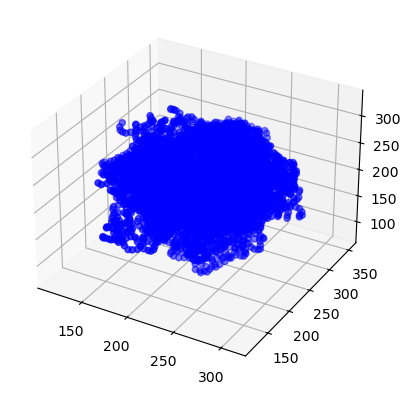

In [3]:

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

File_Path_1 = r'C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\SS_CONSIDERED_SugarRings_output_PDB.pdb'
mrc = MRC_FILE()
mrc.read_mrc(r"C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\emd_3941_normalized.mrc")
mrc.filter_uNet_KA(r"C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\emd_3941.map_key_atoms_2_possibility.mrc")
mrc.filter_uNet_SS(r"C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\emd_3941.map_secondary_strctures_4_possibility.mrc")

p = points()

p.find_coords(mrc,params = 0, threshold=0.50)
p.compress_points_mass(threshold=3)

print("=== Final Coordinates ===")
print(p.mw_coords)
#print(p.merged_plot_coords)
print("==========================")

#final_coords = p.merge_coord()
final_coords = p.mw_coords
# Create a new figure
fig = plt.figure()

# Add a 3D subplot
ax = fig.add_subplot(111, projection='3d')

# Plot the mass weighted points
#ax.scatter(p.mw_coords[:, 0], p.mw_coords[:, 1], p.mw_coords[:, 2], color='b')
ax.scatter(final_coords[:, 0], final_coords[:, 1], final_coords[:, 2], color='b')

# Plot the merged points
#ax.scatter(merged_plot_coords[:, 0], merged_plot_coords[:, 1], merged_plot_coords[:, 2], color='r')

plt.show()

#final_coords = p.final_coords

def write_as_PDB(final_coords, output_file_name):   # add additional args as needed

    with open(output_file_name, "w") as text_file:
        
        for i, values in enumerate(final_coords):                        
            print(f"ATOM  {str(i+1):>5} {' P':<4}{' '}{'U':>3} {'A'}{'1':>4}{' '}   {final_coords[i][2]:.3f} {final_coords[i][1]:.3f} {final_coords[i][0]:.3f} {'1.00':>6}{'16.00':>6}{'':6}{' ':<4}{'C':>2}", file=text_file)
        

write_as_PDB(final_coords, File_Path_1)      

p_2 = points()



    


In [4]:
from collections import deque
from scipy.spatial import KDTree

def filter_data_by_threshold(data, threshold):
    
    uNet_filtrered_map = np.copy(data)
    uNet_filtrered_map[uNet_filtrered_map <= threshold] = 0
    indexes_nonZero = np.nonzero(uNet_filtrered_map)
    
    coordinate_output = np.transpose(indexes_nonZero)

    return uNet_filtrered_map, coordinate_output

    

             


def bfs(data, search, early_stop): #Data will be the filtered uNet map
    
    #Lets make the array a 2D array, axis 0 is each Nonzero point, axis 1 is the x,y,z coordinates
    indices = np.nonzero(data) #Data is the map file with the treshold applied indexes are where it is non zero
    indices_2d = np.transpose(indices) #Make this into an array of 3D coordinates
    print(indices_2d)
    
    print("Number of Points to Traverse", indices_2d.shape[0]) 
    
    visited = np.zeros(data.shape, dtype=bool)
    #print("Visited",visited.shape)
    blob = {}

    # Define the directions for up, down, left, right, front, center, back
    directions = np.array([(0, 0, 1), (0, 0, -1), (0, 1, 0), (0, -1, 0), (1, 0, 0), (-1, 0, 0)])
    
    #pbar = tqdm(data.size)

    for start in tqdm(indices_2d):
        start = tuple(start)
                
        #print("Did I visit",visited[start])
        if visited[start]:
            continue

        queue = deque([start])
        visited[start] = True
        blob[start] = [start]
        
        new_blob_start = 1

        while queue:
            
            x, y, z = queue.popleft()
            neighbors = np.array([x, y, z]) + directions
            
            #Ensure neighbors are within boundaries
            valid_neighbors = np.all((neighbors >= 0) & (neighbors < np.array(data.shape)), axis=1)
            
            unvisited_neighbors = neighbors[valid_neighbors]
            unvisited_neighbors = unvisited_neighbors[~visited[tuple(unvisited_neighbors.T)]]
            visited[tuple(unvisited_neighbors.T)] = True
            
            
            for point in unvisited_neighbors:
                x,y,z = point[0], point[1], point[2]
                if data[x,y,z] != 0:
                    blob[start].append(tuple([x,y,z]))
                    queue.append(tuple(point))
            
            
            
            # #print("visited[neighbors]",np.all(visited[tuple(neighbors.T)] != 0 & neighbors.T < np.array(data.shape)))
            # #print("visited[neighbors] 2",np.all(visited[neighbors] > 0, axis=1))

            # # Ensure the neighbors are within the data boundaries
            # #print("Found Neighbors", neighbors)
            # valid_neighbors = np.all((neighbors >= 0) & (neighbors < np.array(data.shape)), axis=1)
            # #print("Valid Neighbors",valid_neighbors)

            # # Only consider neighbors that have not been visited
            # unvisited_neighbors = neighbors[valid_neighbors]
            # unvisited_neighbors = unvisited_neighbors[~visited[tuple(unvisited_neighbors.T)]]
            
            # unvisited_neighbors = unvisited_neighbors[data[tuple(unvisited_neighbors.T)] != 0]

            # if len(unvisited_neighbors) == 0:
            #     new_blob_start += 1
            #     continue
            # queue.extend([tuple(neighbor) for neighbor in unvisited_neighbors])
            # visited[tuple(unvisited_neighbors.T)] = True
            # blob[start].extend([tuple(neighbor) for neighbor in unvisited_neighbors])
            
            
                
            
            
            # if(early_stop == True):
            #     break

            
            # #break (seem to get more coordinates like this)
            # #pbar.update(len(unvisited_neighbors))  # Update tqdm with the number of unvisited neighbors
    
    #pbar.close()
    print("Size of Blob", len(blob))
    print("Number of New Blob Starts", new_blob_start)

    return blob

In [5]:
filtered_uNet_Map, coords_uNet = filter_data_by_threshold(mrc.uNet_map_KA, 0.5) #Filters data by threshold of 0.5

all_blobs = bfs(filtered_uNet_Map, 1, early_stop = False) #Performs BFS on the filtered data

[[114 215 210]
 [114 216 213]
 [114 216 214]
 ...
 [442 411 300]
 [442 411 350]
 [442 411 400]]
Number of Points to Traverse 88730


100%|██████████| 88730/88730 [00:05<00:00, 15945.42it/s]

Size of Blob 4445
Number of New Blob Starts 1


In [6]:
# print("filtered_uNet_Map",filtered_uNet_Map.shape)
# data = np.copy(filtered_uNet_Map)
# indices = np.nonzero(data) #Data is the map file with the treshold applied indexes are where it is non zero
# indices_2d = np.transpose(indices) #Make this into an array of 3D coordinates
# print(indices_2d)
# visited = np.zeros(filtered_uNet_Map.shape, dtype=bool)
# print("Visited Array",  visited.shape)


# one_point = (114, 215, 210)
# directions = np.array([(0, 0, 1), (0, 0, -1), (0, 1, 0), (0, -1, 0), (1, 0, 0), (-1, 0, 0)])
# six_points = np.array([one_point[0], one_point[1], one_point[2]]) + directions
# six_points = np.resize(six_points, (6,3))
# six_points = list(map(tuple, six_points))

# print("Pretend we visited the first point", six_points[0])
# visited[six_points[0]] = True
# print(visited[tuple(six_points[0])])

# six_points = np.array(six_points)
# valid_neighbors = np.all((six_points >= 0) & (six_points < np.array(filtered_uNet_Map.shape)), axis=1)
# print("Are we within bounds",valid_neighbors)
# unvisited_neighbors = six_points[valid_neighbors]
# print(unvisited_neighbors)
# print("Tuple Conversion")
# # unvisited_neighbors = np.array([tuple(row) for row in unvisited_neighbors])
# print(unvisited_neighbors)   
# #print(tuple(unvisited_neighbors.T))
# print("We have visited points already",visited[tuple(unvisited_neighbors.T)])
# unvisited_neighbors = unvisited_neighbors[~visited[tuple(unvisited_neighbors.T)]]
# #unvisited_neighbors = list(map(tuple, unvisited_neighbors))

# print("Points that are visited after checking visited matrix", unvisited_neighbors)

# #unvisited_neighbors = unvisited_neighbors[data[tuple(unvisited_neighbors.T)] != 0]
# #print("Data", [print(data[point]) for point in unvisited_neighbors if data[point] != 0])

# for point in unvisited_neighbors:
#     x,y,z = point[0], point[1], point[2]
#     if data[x,y,z] != 0:
#         #print("Data", data[point[0],point[1],point[2]])
#     visited[x,y,z] = True
        
    

# print("We have visited points already",visited[tuple(unvisited_neighbors.T)])
# visited[tuple(unvisited_neighbors.T)] = False
# print("We have visited points already",visited[tuple(unvisited_neighbors.T)])
# #print("Unvisited points with probabilities larger than zero",data[unvisited_neighbors] != 0)

In [27]:
first_key = list(all_blobs.keys())[0]

mrc_raw = mrc.originial_density
test_blobs = np.array(all_blobs[first_key])
# print(mrc_raw[tuple(test_blobs.T)]*10)
# print("Density of Blob", mrc_raw)
blob = np.array(all_blobs[first_key])

mrc_raw = mrc.originial_density

#print("Blob", mrc_raw[blob])

def center_of_mass_from_dict(blob,data):
    total_density = []
    com_coords = []
    for key in blob.keys():
        
        current_blob = np.array(blob[key])
        com_x, com_y, com_z = current_blob[:,0].astype(float), current_blob[:,1].astype(float), current_blob[:,2].astype(float)
        
        mass_of_blob = data[tuple(np.array(blob[key]).T)]*10
        sum_mass = np.sum(mass_of_blob)
        
        if(sum_mass != 0):
            com_x = np.sum(np.dot(com_x,mass_of_blob)) / sum_mass
            com_y = np.sum(np.dot(com_y,mass_of_blob)) / sum_mass
            com_z = np.sum(np.dot(com_z,mass_of_blob)) / sum_mass
            
            print("Center of Mass", com_x, com_y, com_z)
            total_density.append(sum_mass)
            com_coords.extend([com_x, com_y, com_z])
            
    return np.array(com_coords).reshape(-1, 3), total_density

comb = center_of_mass_from_dict(all_blobs, mrc_raw)

# mrc_raw = mrc.originial_density
# center_of_mass_blob = center_of_mass_from_dict(all_blobs, mrc_raw)



Center of Mass 115.3771115279149 215.27367260600758 210.0962974133471
Center of Mass 115.0 215.0 214.0
Center of Mass 115.14275943563878 217.47185470622117 216.75597117386192
Center of Mass 118.4190702249684 207.53443060447404 223.91448462644036
Center of Mass 118.63002647180761 214.53240919647521 204.35998055191692
Center of Mass 121.30840103189861 207.30811116887742 207.61697647592797
Center of Mass 121.38801950376543 202.15411085995748 209.83256672439452
Center of Mass 121.72596805662408 215.76328520462366 193.11226179051397
Center of Mass 120.84588315569066 218.07018743112585 186.68581496416306
Center of Mass 120.0 218.0 188.0
Center of Mass 124.1011016164443 203.46236399336834 224.24008466093414
Center of Mass 123.60828928840806 213.04979875337722 201.99839281460967
Center of Mass 124.8938924790374 228.3807825592257 206.4785949659115
Center of Mass 125.20462797025897 216.52570531804503 183.52970084770502
Center of Mass 124.98424300219351 228.74297362891303 201.7993846067373
Center

In [ ]:
def merge_coord(mw_merge_dens, mw_coords, rcut=.15, d_cut=3):
        #First Determine Fraction Density
        max_dens = np.max(mw_merge_dens)
        min_dens = np.min(mw_merge_dens)
        
        print(f"Max Dens: {max_dens} and Min Dens: {min_dens}")
        frac_dens = 1/(max_dens - min_dens)
        
        stock_indexes = np.ones(len(mw_merge_dens))
        member_indexes = np.arange(len(mw_merge_dens))
        stock_indexes[((mw_merge_dens - min_dens)*frac_dens) < rcut] = 0
        
        
        print("Merging Coordinates...")
        for i in tqdm(range(0, len(mw_merge_dens))):
            for j in range(i+1, len(mw_merge_dens)):
                if np.linalg.norm(mw_coords[i] - mw_coords[j]) < d_cut:
                    if(mw_merge_dens[i] > mw_merge_dens[j]):
                        member_indexes[j] = i
                        stock_indexes[j] = 0
                    else:
                        member_indexes[i] = j
                        stock_indexes[i] = 0
                        break
        
        print("Checking for relevant parent child relationships...")
        for i in tqdm(range(0, len(mw_merge_dens))):
            child = int(member_indexes[i])
            while child != member_indexes[i]:
                child = int(member_indexes[i])
            member_indexes[i] = child
            
        num_merge2 = np.count_nonzero(stock_indexes)
        merged_coords = []
        
        print("Preparing Final Coordinates...")
        for i in tqdm(range(0,len(stock_indexes))):
            if stock_indexes[i] == 0:
                continue
            
            merged_coords.extend(mw_coords[i,:3])
            
   
        return merged_coords    
        

In [34]:
print("Number of Blobs: ", len(all_blobs))
print(all_blobs)
#print("Blob Keys: ", all_blobs.keys()) # Print the keys of the blobs
all_blobs_keys = np.array(list(all_blobs.keys()))
mrc_raw = mrc.originial_density

# #def plot_blobs(blobs):
#     fig = plt.figure()
#     ax = fig.add_subplot(111, projection='3d')
    
    
    
#     for blob in all_blobs:
#         #print(blob)
#         blob = np.array(blob)
#         ax.scatter(blob[0],blob[1],blob[2])
    
#     plt.show()


# def centroids_from_dict(blobs):
    
#     centroids = []
#     for blob in blobs:
#         MRC_density_temp = []
#         MRC_density_temp.append(mrc_raw[blob])
#         MRC_density = np.array(MRC_density_temp)
                        
#         blob = np.array(blob).astype(float)
        
#         coord_mass = MRC_density[0]*blob[]
#         print("coord_mass",coord_mass)
#         total_coord_mass = np.sum(coord_mass, axis=0) 
#         print("total_coord_mass",total_coord_mass) 
#         total_mass = np.sum(MRC_density)
#         com = [total_coord_mass[0]/total_mass, total_coord_mass[1]/total_mass, total_coord_mass[2]/total_mass]
#         if np.isnan(com).any():
#             continue
        
#         # if com.size !=3:
#         #     print("Error",com)
        
#         print(com)
#         centroids.extend(com)
    
#     centroids = np.array(centroids)
#     centroids = centroids.reshape(-1,)
    
#     return centroids

def write_as_xyz(final_coords, output_file_name, title):
    with open(f"{output_file_name}.xyz", 'w') as xyz_file:
        xyz_file.write(f"{len(final_coords)}\n{title}\n")
        for i in final_coords:
            xyz_file.write("{:4} {:11.6f} {:11.6f} {:11.6f}\n".format(
                "C", i[2], i[1], i[0]))
            
File_Path_3 = r'C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\blobs.pdb'
File_Path_4 = r'C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\blobsmassweight'
#blob_centroids = centroids_from_dict(all_blobs)


write_as_xyz(comb , File_Path_4, "Mikerinos")
# write_as_xyz(blob_centroids, File_Path_3, "shite")
# write_as_PDB(blob_centroids, File_Path_3)
write_as_xyz(coords_uNet, r'C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\filtered_uNet_Map.pdb',str("Filtered uNet Map"))


Number of Blobs:  4445
{(114, 215, 210): [(114, 215, 210), (115, 215, 210), (115, 215, 211), (115, 215, 209), (115, 216, 210), (115, 214, 210), (116, 215, 210), (115, 216, 211), (115, 214, 211), (116, 215, 211), (115, 215, 208), (115, 216, 209), (115, 214, 209), (116, 215, 209), (116, 216, 210), (116, 214, 210), (117, 215, 210), (115, 216, 212), (116, 216, 211), (115, 214, 208), (116, 215, 208), (116, 216, 209), (116, 214, 209), (117, 215, 209), (115, 216, 213), (116, 214, 208), (114, 216, 213), (114, 216, 214)], (115, 215, 214): [(115, 215, 214)], (115, 216, 216): [(115, 216, 216), (115, 217, 216), (115, 217, 217), (115, 218, 216), (116, 217, 216), (115, 218, 217), (115, 218, 218)], (117, 207, 224): [(117, 207, 224), (118, 207, 224), (118, 207, 225), (118, 207, 223), (118, 208, 224), (119, 207, 224), (118, 208, 225), (119, 207, 225), (118, 208, 223), (119, 207, 223), (119, 208, 224), (120, 207, 224), (119, 208, 225), (119, 208, 223)], (118, 214, 203): [(118, 214, 203), (118, 214, 204)

In [32]:
def extract_phosphorus_atoms(input_pdb, output_pdb):
    with open(input_pdb, 'r') as infile, open(output_pdb, 'w') as outfile:
        for line in infile:
            if line.startswith(("ATOM", "HETATM")):
                atom_name = line[76:78].strip()  # Extracting atom name (P is at columns 77-78)
                if atom_name == 'P':
                    outfile.write(line)

output_pdb_file = r'C:\Users\micha\Downloads\emd_3941-20240509T064133Z-001\emd_3941\onlyphosporusAtoms2.pdb' # Replace with your input PDB file path
input_pdb_file = r'C:\Users\micha\Downloads\6eri-pdb-bundle\6eri-pdb-bundle2.pdb'  # The output PDB file with only phosphorus atoms
extract_phosphorus_atoms(input_pdb_file, output_pdb_file)


In [ ]:
# import scipy
# from scipy import stats
# from scipy.stats import gaussian_kde
# from sklearn.mixture import GaussianMixture


# mrc_raw = np.copy(mrc.originial_density)
# densities = []
# centers = []

# first_key = next(iter(all_blobs))
# for key in tqdm(all_blobs):
    
#     #print(all_blobs[key])
#     density = []
#     X = []
#     Y = []
#     Z = []
#     for i in all_blobs[key]:
#         density.append(mrc_raw[i[0], i[1], i[2]])
#         X = [i[0] for i in all_blobs[key]]
#         Y = [i[1] for i in all_blobs[key]]
#         Z = [i[2] for i in all_blobs[key]]

    
#     input_kde = np.transpose(np.array([X, Y, Z, density])).astype(float)
#     if input_kde.shape[0] <= 1:
#         centers.append(input_kde[0][0:3])
#         densities.append(input_kde[0][3])
#         continue
    
#     gmm = GaussianMixture(n_components=1, random_state=0).fit(input_kde)
#     density_val = scipy.stats.multivariate_normal(cov=gmm.covariances_[0], mean=gmm.means_[0]).logpdf(input_kde)
#     argmax_val = input_kde[np.argmax(density)]
#     centers.append(argmax_val[0:3])
#     densities.append(argmax_val[3])
    

In [ ]:
mrc_raw = np.copy(mrc.originial_density)
densities = []
for i,key in enumerate(tqdm(all_blobs)):
    all_blobs[key] = np.array(all_blobs[key])
    densities.extend(mrc_raw[all_blobs[key]])



 10%|█         | 452/4445 [01:14<10:55,  6.09it/s]


MemoryError: Unable to allocate 43.1 MiB for an array with shape (19, 3, 445, 445) and data type float32